# 1 EDA

### 1.1 Imports and Setup

In [5]:
import os
import json
import glob
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

possible_roots = [
    "/kaggle/input",
    "/kaggle/input/competitions"
]

DATA_ROOT = None
for base in possible_roots:
    if not os.path.exists(base):
        continue
    for d in os.listdir(base):
        candidate = os.path.join(base, d)
        if os.path.isdir(candidate):
            train_json = os.path.join(candidate, "train", "annotations_coco.json")
            if os.path.exists(train_json):
                DATA_ROOT = candidate
                break
    if DATA_ROOT:
        break

if DATA_ROOT is None:
    raise FileNotFoundError("Could not find the competition data. Make sure the competition is added to your notebook.")

print("✅ Using DATA_ROOT =", DATA_ROOT)

TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VAL_DIR   = os.path.join(DATA_ROOT, "val")
TEST_CSV  = os.path.join(DATA_ROOT, "test_images.csv")

print("Train exists:", os.path.exists(TRAIN_DIR))
print("Val exists:  ", os.path.exists(VAL_DIR))
print("Test CSV:    ", os.path.exists(TEST_CSV))

sample_clip = os.listdir(os.path.join(TRAIN_DIR, "images"))[0]
sample_img = os.listdir(os.path.join(TRAIN_DIR, "images", sample_clip))[0]
print("Sample image path:", os.path.join(TRAIN_DIR, "images", sample_clip, sample_img))

✅ Using DATA_ROOT = /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
Train exists: True
Val exists:   True
Test CSV:     True
Sample image path: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/train/images/uav0000361_02323_v/0000212.jpg


### 1.2 Load COCO Annotations

In [6]:
with open(os.path.join(TRAIN_DIR, "annotations_coco.json"), "r") as f:
    train_coco = json.load(f)

with open(os.path.join(VAL_DIR, "annotations_coco.json"), "r") as f:
    val_coco = json.load(f)

print("Train images:", len(train_coco["images"]))
print("Train annotations:", len(train_coco["annotations"]))
print("Train categories:", train_coco["categories"])
print("Val images:", len(val_coco["images"]))
print("Val annotations:", len(val_coco["annotations"]))

Train images: 24201
Train annotations: 1616260
Train categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]
Val images: 2846
Val annotations: 146092


### 1.3 Class Distribution

Category map: {1: 'person', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'bus', 8: 'motor'}


/tmp/ipykernel_49/2115043423.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_values, palette="viridis")


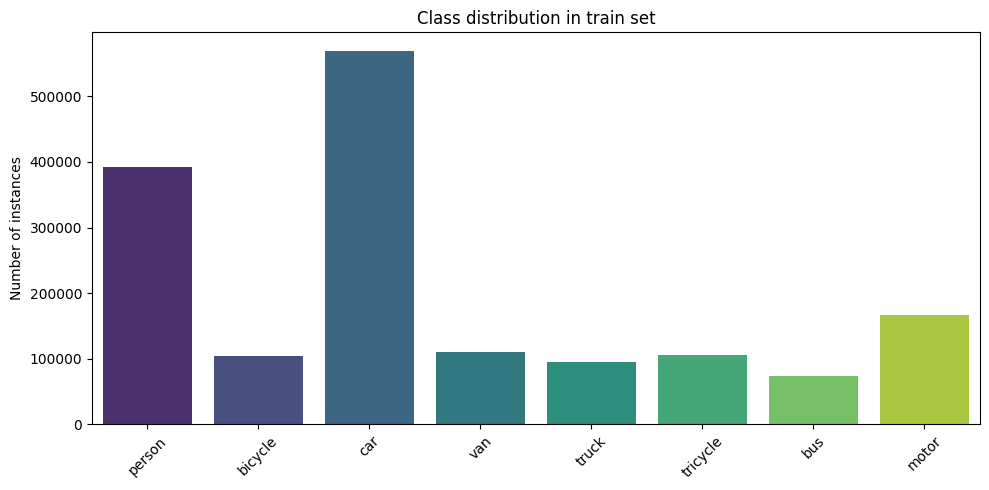

      class   count  percentage
0    person  392544       24.29
1   bicycle  104098        6.44
2       car  569144       35.21
3       van  110783        6.85
4     truck   94341        5.84
5  tricycle  105192        6.51
6       bus   73496        4.55
7     motor  166662       10.31


In [7]:
cat_id_to_name = {c["id"]: c["name"] for c in train_coco["categories"]}
print("Category map:", cat_id_to_name)

class_counts = Counter([ann["category_id"] for ann in train_coco["annotations"]])
class_names  = [cat_id_to_name[cid] for cid in sorted(class_counts.keys())]
class_values = [class_counts[cid] for cid in sorted(class_counts.keys())]

plt.figure(figsize=(10, 5))
sns.barplot(x=class_names, y=class_values, palette="viridis")
plt.title("Class distribution in train set")
plt.ylabel("Number of instances")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df_classes = pd.DataFrame({"class": class_names, "count": class_values})
df_classes["percentage"] = (df_classes["count"] / df_classes["count"].sum() * 100).round(2)
print(df_classes)

**Severe Class Imbalance**: The dataset is dominated by `car` (35.2%) and `person` (24.3%) classes. In contrast, classes like `bus` (4.5%), `truck` (5.8%), and `bicycle` (6.4%) are underrepresented. 
   * *Implication*: We will need to use techniques such as Focal Loss, class-weighted sampling, or Copy-Paste augmentation to prevent the model from ignoring rare classes.

### 1.4 Object Size Distribution (COCO categories)

Small  (<32x32): 275347  (24.91%)
Medium (<96x96): 702004 (63.50%)
Large  (>=96x96): 128165  (11.59%)


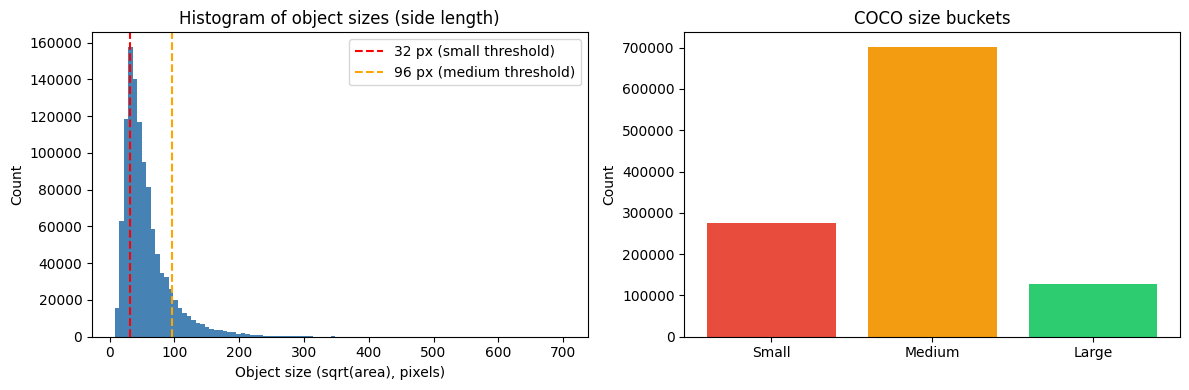

In [8]:
areas = [ann["area"] for ann in train_coco["annotations"] if ann.get("iscrowd", 0) == 0]
areas = np.array(areas)

small  = np.sum(areas < 32**2)
medium = np.sum((areas >= 32**2) & (areas < 96**2))
large  = np.sum(areas >= 96**2)
total  = len(areas)

print(f"Small  (<32x32): {small}  ({small/total*100:.2f}%)")
print(f"Medium (<96x96): {medium} ({medium/total*100:.2f}%)")
print(f"Large  (>=96x96): {large}  ({large/total*100:.2f}%)")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(np.sqrt(areas), bins=100, color="steelblue")
plt.xlabel("Object size (sqrt(area), pixels)")
plt.ylabel("Count")
plt.title("Histogram of object sizes (side length)")
plt.axvline(32, color="red",    linestyle="--", label="32 px (small threshold)")
plt.axvline(96, color="orange", linestyle="--", label="96 px (medium threshold)")
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(["Small", "Medium", "Large"], [small, medium, large], color=["#e74c3c","#f39c12","#2ecc71"])
plt.title("COCO size buckets")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**Object Scale Distribution**: The size histogram reveals a large peak around 30-50 pixels. According to COCO thresholds, 63.5% of objects are Medium (32-96px) and 24.9% are Small (<32px). 
   * *Implication*: Training at a standard 640x640 resolution will destroy the features of small objects. We must train at a higher resolution (e.g., 1024x1024 or 1280x1280) and strongly consider using SAHI (Slicing Aided Hyper Inference) during inference.

### 1.5 Objects Per Frame (Density)

Mean objects per frame: 66.78
Median: 54.0
Max: 342
Frames with 0 objects: 3


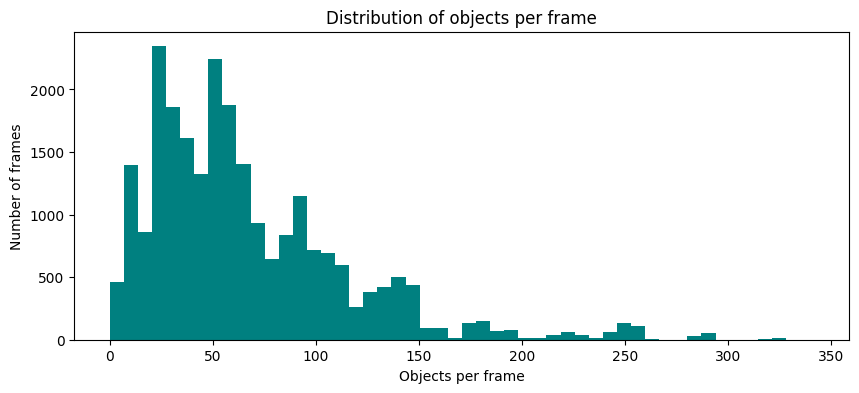

In [9]:
per_image = defaultdict(int)
for ann in train_coco["annotations"]:
    per_image[ann["image_id"]] += 1

counts_per_image = np.array([per_image.get(img["id"], 0) for img in train_coco["images"]])

print("Mean objects per frame:", counts_per_image.mean().round(2))
print("Median:", np.median(counts_per_image))
print("Max:", counts_per_image.max())
print("Frames with 0 objects:", int((counts_per_image == 0).sum()))

plt.figure(figsize=(10, 4))
plt.hist(counts_per_image, bins=50, color="teal")
plt.xlabel("Objects per frame")
plt.ylabel("Number of frames")
plt.title("Distribution of objects per frame")
plt.show()

**High Scene Density**: On average, there are 66.8 objects per frame, with a maximum of 342 objects in a single frame.
   * *Implication*: Standard Non-Maximum Suppression (NMS) might suppress valid neighboring boxes in such crowded scenes. We should experiment with Soft-NMS. For query-based models (like RT-DETR), we must ensure the number of queries is large enough (e.g., >300) to cover the maximum density.

### 1.6 Variation Across Clips

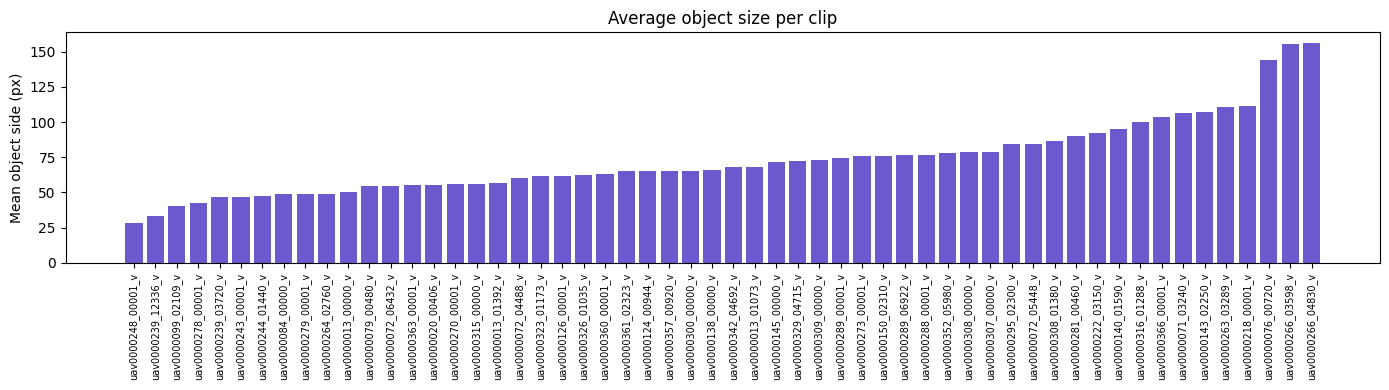

       mean_side_px     n_objects
count     56.000000     56.000000
mean      73.297546  19741.357143
std       27.068001  16073.296195
min       28.516727    706.000000
25%       55.317156   8518.500000
50%       67.154547  16044.500000
75%       84.271855  25812.250000
max      156.017841  64916.000000


In [10]:
img_id_to_clip = {}
for img in train_coco["images"]:
    clip = img.get("video") or img["file_name"].split("/")[-2]
    img_id_to_clip[img["id"]] = clip

clip_to_sizes = defaultdict(list)
for ann in train_coco["annotations"]:
    if ann.get("iscrowd", 0) == 0:
        clip = img_id_to_clip[ann["image_id"]]
        clip_to_sizes[clip].append(ann["area"])

clip_stats = pd.DataFrame([
    {"clip": c, "mean_side_px": np.sqrt(np.mean(v)), "n_objects": len(v)}
    for c, v in clip_to_sizes.items()
]).sort_values("mean_side_px")

plt.figure(figsize=(14, 4))
plt.bar(range(len(clip_stats)), clip_stats["mean_side_px"], color="slateblue")
plt.xticks(range(len(clip_stats)), clip_stats["clip"], rotation=90, fontsize=7)
plt.ylabel("Mean object side (px)")
plt.title("Average object size per clip")
plt.tight_layout()
plt.show()

print(clip_stats.describe())

**High Intra-Clip Variance**: The average object size varies drastically across different video clips (ranging from 28px to 156px), representing different camera altitudes and scene types (highways vs. fields).
   * *Implication*: This confirms that we **must** split our validation set by video clip (GroupKFold) to avoid data leakage. Furthermore, we must use aggressive scale augmentation during training to make the model robust to these variations.

### 1.7 Ground-Truth Visualization

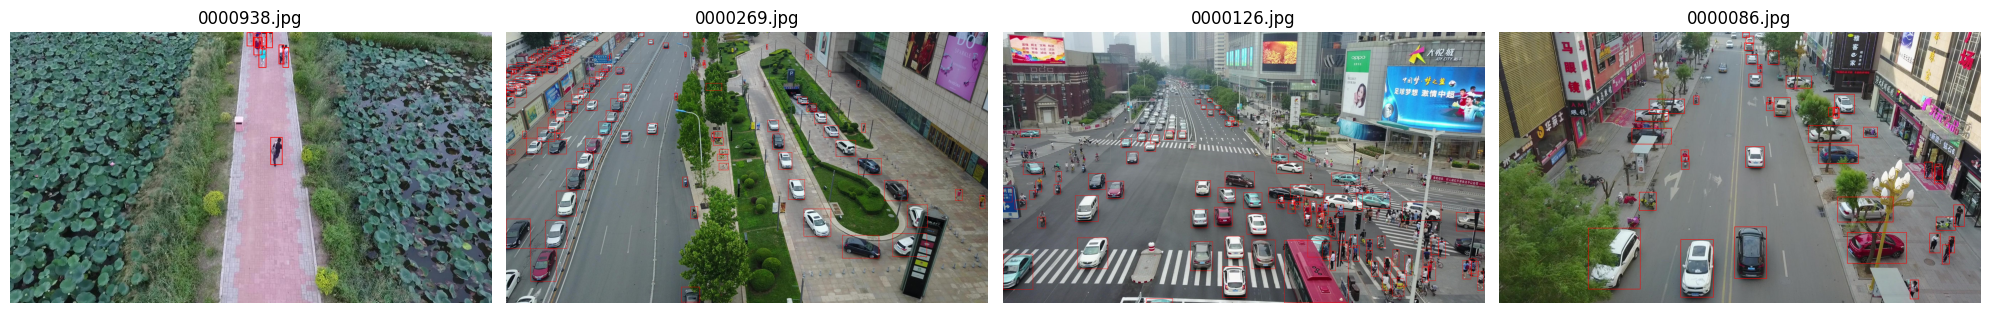

In [11]:
from PIL import Image, ImageDraw

def visualize_gt(coco, root, n=4, seed=28):
    random.seed(seed)
    img_entries = random.sample(coco["images"], n)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]

    anns_by_img = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_img[ann["image_id"]].append(ann)

    for ax, img_info in zip(axes, img_entries):
        img_path = os.path.join(root, img_info["file_name"])
        image = Image.open(img_path).convert("RGB")
        draw = ImageDraw.Draw(image)
        for ann in anns_by_img[img_info["id"]]:
            x, y, w, h = ann["bbox"]
            color = "red" if ann.get("iscrowd", 0) == 0 else "gray"
            draw.rectangle([x, y, x + w, y + h], outline=color, width=2)
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(img_info["file_name"].split("/")[-1])
    plt.tight_layout()
    plt.show()

visualize_gt(train_coco, TRAIN_DIR, n=4)

### 1.8 Anchor Analysis via K-Means (for RetinaNet)

Recommended anchor (w, h) from your data:
  w=23.8, h=33.7   aspect_ratio=0.71
  w=52.2, h=39.3   aspect_ratio=1.33
  w=40.1, h=70.5   aspect_ratio=0.57
  w=87.8, h=52.2   aspect_ratio=1.68
  w=84.7, h=106.5   aspect_ratio=0.80
  w=145.9, h=72.8   aspect_ratio=2.00
  w=225.3, h=111.8   aspect_ratio=2.02
  w=158.3, h=173.7   aspect_ratio=0.91
  w=336.4, h=221.7   aspect_ratio=1.52


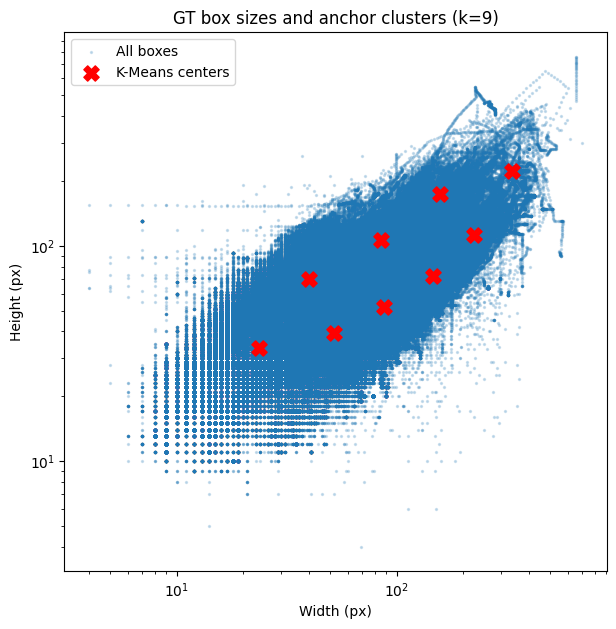

In [12]:
from sklearn.cluster import KMeans

wh = np.array([[ann["bbox"][2], ann["bbox"][3]]
               for ann in train_coco["annotations"] if ann.get("iscrowd", 0) == 0])

k = 9
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(wh)
centers = kmeans.cluster_centers_
centers = centers[np.argsort(centers[:, 0] * centers[:, 1])]  # sort by area

print("Recommended anchor (w, h) from your data:")
for c in centers:
    print(f"  w={c[0]:.1f}, h={c[1]:.1f}   aspect_ratio={c[0]/c[1]:.2f}")

plt.figure(figsize=(7, 7))
plt.scatter(wh[:, 0], wh[:, 1], s=2, alpha=0.2, label="All boxes")
plt.scatter(centers[:, 0], centers[:, 1], c="red", s=120, marker="X", label="K-Means centers")
plt.xlabel("Width (px)"); plt.ylabel("Height (px)")
plt.title("GT box sizes and anchor clusters (k=9)")
plt.xscale("log"); plt.yscale("log")
plt.legend()
plt.show()

**Custom Anchor Configuration**: K-Means clustering (k=9) on the ground-truth bounding boxes produced highly specific anchor sizes (e.g., 23.8x33.7, 52.2x39.3, 145.9x72.8), which are significantly smaller than the default COCO anchors.
   * *Implication*: We will use these exact dimensions to configure the anchors for our anchor-based models (RetinaNet and Faster R-CNN) to maximize their matching rate with ground-truth objects.

###  1.9 Image Resolution Analysis

           image_id                         file_name      clip  frame  width  \
0  clip_001_0000001  test/images/clip_001/0000001.jpg  clip_001      1   1920   
1  clip_001_0000002  test/images/clip_001/0000002.jpg  clip_001      2   1920   
2  clip_001_0000003  test/images/clip_001/0000003.jpg  clip_001      3   1920   
3  clip_001_0000004  test/images/clip_001/0000004.jpg  clip_001      4   1920   
4  clip_001_0000005  test/images/clip_001/0000005.jpg  clip_001      5   1920   

   height  
0    1080  
1    1080  
2    1080  
3    1080  
4    1080  

Columns: ['image_id', 'file_name', 'clip', 'frame', 'width', 'height']


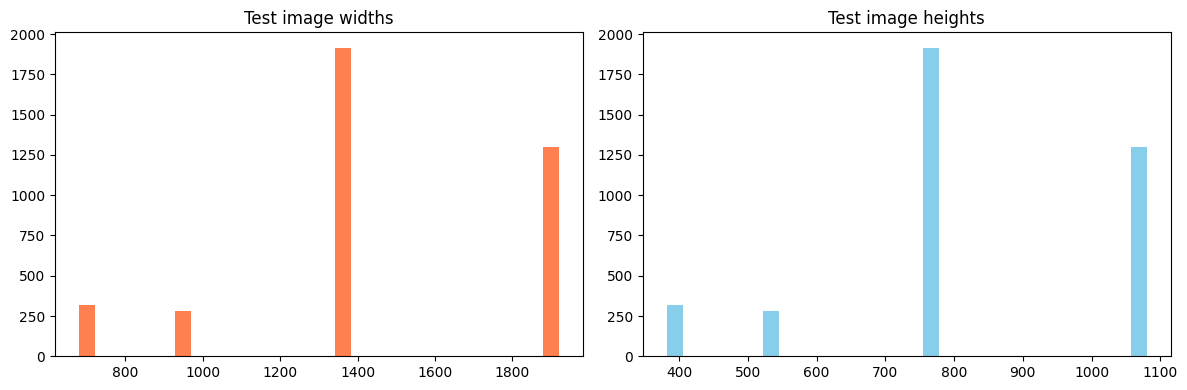


Test clips: 48
Total test frames: 3811
Resolution combinations:
width  height
1360   764       1474
1920   1080       991
1344   756        441
680    382        321
1904   1072       305
dtype: int64


In [13]:
test_df = pd.read_csv(TEST_CSV)
print(test_df.head())
print("\nColumns:", test_df.columns.tolist())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(test_df["width"], bins=30, color="coral")
plt.title("Test image widths")
plt.subplot(1, 2, 2)
plt.hist(test_df["height"], bins=30, color="skyblue")
plt.title("Test image heights")
plt.tight_layout()
plt.show()

print("\nTest clips:", test_df["clip"].nunique())
print("Total test frames:", len(test_df))
print("Resolution combinations:")
print(test_df.groupby(["width", "height"]).size().sort_values(ascending=False).head())

**Variable Test Resolutions**: Test images come in 4 distinct resolutions, with the majority being 1920x1080 and 1360x764.
   * *Implication*: The inference pipeline must properly resize inputs using letterboxing and accurately scale the predicted bounding boxes back to the original pixel coordinates before writing the `submission.csv`.

### 1.10 Create and Save the Validation Split (by CLIP, not frame)

In [14]:
# Get unique clips in the TRAIN set
train_clips = sorted({img["file_name"].split("/")[-2] for img in train_coco["images"]})
print(f"Total train clips: {len(train_clips)}")
print(train_clips[:5])

random.seed(28)
random.shuffle(train_clips)
n_val = max(1, int(0.2 * len(train_clips)))
val_clips   = set(train_clips[:n_val])
train_clips = set(train_clips[n_val:])

print("Train clips:", len(train_clips))
print("Val clips:  ", len(val_clips))
print("Overlap:", train_clips & val_clips)  # Must be empty

# Save lists for later use by all 4 experiments
OUT_DIR = "/kaggle/working/splits"
os.makedirs(OUT_DIR, exist_ok=True)
with open(os.path.join(OUT_DIR, "train_clips.txt"), "w") as f:
    f.write("\n".join(sorted(train_clips)))
with open(os.path.join(OUT_DIR, "val_clips.txt"), "w") as f:
    f.write("\n".join(sorted(val_clips)))
print("Saved splits to", OUT_DIR)

Total train clips: 56
['uav0000013_00000_v', 'uav0000013_01073_v', 'uav0000013_01392_v', 'uav0000020_00406_v', 'uav0000071_03240_v']
Train clips: 45
Val clips:   11
Overlap: set()
Saved splits to /kaggle/working/splits


### 1.11 Summary

In [15]:
print(f"""
=== EDA SUMMARY ===

1. Class imbalance:
   - Most common class: {class_names[int(np.argmax(class_values))]} ({max(class_values)} instances)
   - Rarest class:      {class_names[int(np.argmin(class_values))]} ({min(class_values)} instances)

2. Object sizes:
   - Small objects (<32px):  {small/total*100:.1f}%
   - Medium objects:         {medium/total*100:.1f}%
   - Large objects:          {large/total*100:.1f}%
   => Training at 1280x1280 + SAHI at inference recommended.

3. Density:
   - Mean objects per frame: {counts_per_image.mean():.1f}
   - Max objects per frame:  {counts_per_image.max()}

4. Recommended anchors (K-Means k=9) — see Cell 8 printout.

5. Validation split:
   - {len(train_clips)} train clips, {len(val_clips)} val clips (GroupKFold by clip).
""")


=== EDA SUMMARY ===

1. Class imbalance:
   - Most common class: car (569144 instances)
   - Rarest class:      bus (73496 instances)

2. Object sizes:
   - Small objects (<32px):  24.9%
   - Medium objects:         63.5%
   - Large objects:          11.6%
   => Training at 1280x1280 + SAHI at inference recommended.

3. Density:
   - Mean objects per frame: 66.8
   - Max objects per frame:  342

4. Recommended anchors (K-Means k=9) — see Cell 8 printout.

5. Validation split:
   - 45 train clips, 11 val clips (GroupKFold by clip).

